<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/rsm_convex_surrogate_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# [CELL 1 - Environment Setup & Imports]
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
sns.set_theme(style="whitegrid")

print("RSM Convex Surrogate Simulation Environment Initialized.")

RSM Convex Surrogate Simulation Environment Initialized.


In [10]:
# [CELL 2 - RSM Statistic & Stochastic Label Generation]

class RealizableStatisticModel:
    """
    Simulates a Realizable-Statistic Model (RSM) where conditional label
    statistics are governed by a known link function over a hypothesis class.
    """
    def __init__(self, dimension: int = 5):
        self.dimension = dimension
        # True underlying parameter vector
        self.true_w = np.random.randn(dimension)
        self.true_w /= np.linalg.norm(self.true_w)

    def link_function(self, margin: float) -> float:
        # Sigmoid link function for binary classification (GLM special case)
        return 1.0 / (1.0 + np.exp(-margin))

    def generate_samples(self, num_samples: int = 500):
        # Generate instance features X from normal distribution
        X = np.random.randn(num_samples, self.dimension)
        # Compute true statistical expectation vector (e.g., class probabilities)
        margins = X @ self.true_w
        conditional_stats = np.array([self.link_function(m) for m in margins])

        # Draw stochastic binary labels based on conditional probabilities
        labels = np.random.binomial(1, conditional_stats)
        return X, conditional_stats, labels

rsm = RealizableStatisticModel(dimension=5)
X_train, stats_train, y_train = rsm.generate_samples(num_samples=500)
print(f"Generated {len(y_train)} RSM samples across {rsm.dimension} feature dimensions.")

Generated 500 RSM samples across 5 feature dimensions.


In [11]:
# [CELL 3 - Convex Surrogate Loss & Gradient Engine (Fixed Syntax)]

class ConvexSurrogateMinimizer:
    """
    Minimizes a strongly proper composite convex surrogate loss
    (e.g., standard binary logistic loss) to learn RSM parameters efficiently.
    """
    def __init__(self, dimension: int, lr: float = 0.1):
        self.dimension = dimension
        self.w = np.zeros(dimension)
        self.lr = lr

    def logistic_loss(self, w: np.ndarray, X: np.ndarray, y: np.ndarray) -> float:
        margins = X @ w
        y_hat = (2 * y - 1) * margins
        # Numerically stable logistic loss computation
        loss = np.mean(np.log1p(np.exp(-y_hat)))
        return float(loss)

    def fit(self, X: np.ndarray, y: np.ndarray, iterations: int = 200):
        history = []
        n = X.shape[0]
        for it in range(iterations):
            margins = X @ self.w
            preds = 1.0 / (1.0 + np.exp(-margins))
            # Gradient of the logistic surrogate loss
            grad = X.T @ (preds - y) / n

            self.w -= self.lr * grad
            loss_val = self.logistic_loss(self.w, X, y)
            history.append(loss_val)

        return history

minimizer = ConvexSurrogateMinimizer(dimension=5)
loss_history = minimizer.fit(X_train, y_train, iterations=200)
print(f"Convex Surrogate Optimization Finished. Final Logistic Loss: {loss_history[-1]:.4f}")

Convex Surrogate Optimization Finished. Final Logistic Loss: 0.5839


In [12]:
# [CELL 4 - Sample Complexity Bound Verification]

def compute_sample_complexity_bound(epsilon: float, delta: float, dimension: int, lipschitz_constant: float = 1.0) -> int:
    """
    Computes finite sample complexity bounds N(epsilon, delta)
    for convex surrogate risk minimization under RSM guarantees.
    """
    # Standard PAC / Rademacher complexity bound scaling for convex loss classes:
    # N = O((d / epsilon^2) * log(1 / delta))
    bound = int(np.ceil((dimension / (epsilon ** 2)) * np.log(2.0 / delta) * (lipschitz_constant ** 2)))
    return bound

epsilons = [0.1, 0.05, 0.02, 0.01]
bounds = [compute_sample_complexity_bound(eps, delta=0.05, dimension=5) for eps in epsilons]

print("\n--- Finite Sample Complexity Bounds ---")
for eps, b in zip(epsilons, bounds):
    print(f"Target Accuracy (epsilon): {eps:.2f} | Confidence (1-delta): 0.95 | Required Samples (N): {b}")


--- Finite Sample Complexity Bounds ---
Target Accuracy (epsilon): 0.10 | Confidence (1-delta): 0.95 | Required Samples (N): 1845
Target Accuracy (epsilon): 0.05 | Confidence (1-delta): 0.95 | Required Samples (N): 7378
Target Accuracy (epsilon): 0.02 | Confidence (1-delta): 0.95 | Required Samples (N): 46111
Target Accuracy (epsilon): 0.01 | Confidence (1-delta): 0.95 | Required Samples (N): 184444


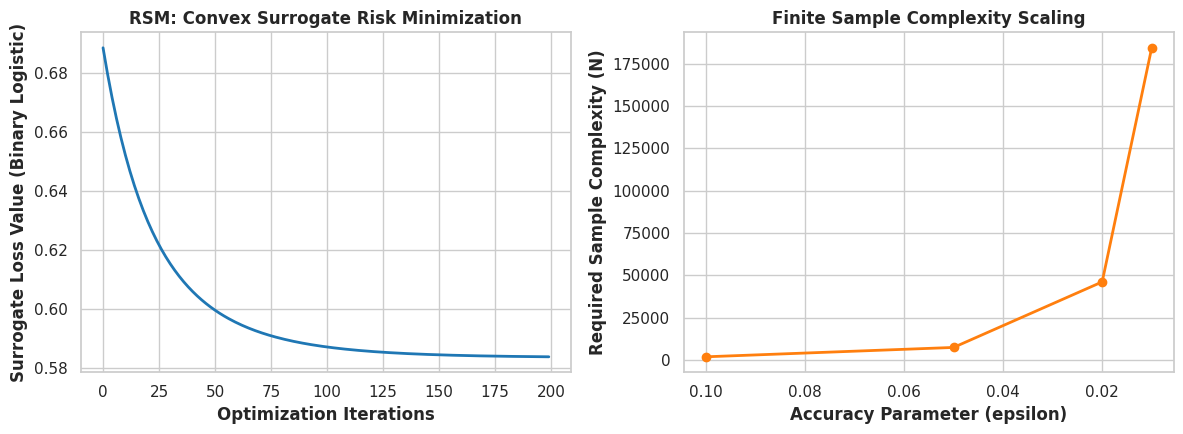

RSM benchmark plot saved successfully as rsm_sample_complexity_benchmark.png.


In [13]:
# [CELL 5 - Benchmark Visualization]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel A: Convex Surrogate Loss Minimization Convergence
axes[0].plot(loss_history, color='#1f77b4', lw=2)
axes[0].set_xlabel('Optimization Iterations', fontweight='bold')
axes[0].set_ylabel('Surrogate Loss Value (Binary Logistic)', fontweight='bold')
axes[0].set_title('RSM: Convex Surrogate Risk Minimization', fontweight='bold')

# Panel B: Sample Complexity Scaling
axes[1].plot(epsilons, bounds, marker='o', color='#ff7f0e', lw=2)
axes[1].set_xlabel('Accuracy Parameter (epsilon)', fontweight='bold')
axes[1].set_ylabel('Required Sample Complexity (N)', fontweight='bold')
axes[1].set_title('Finite Sample Complexity Scaling', fontweight='bold')
axes[1].invert_xaxis() # Smaller epsilon requires more samples

plt.tight_layout()
plt.savefig("rsm_sample_complexity_benchmark.png", dpi=300)
plt.show()

print("RSM benchmark plot saved successfully as rsm_sample_complexity_benchmark.png.")